# Part Two: paired comparison of both Ani winners

**Retain Ani's 0.58688 submission. No new recipe passed the rule fixed before testing, so no new numbered Kaggle submission was promoted or added.**

Read `IMPROVEMENT_PROTOCOL.md` for the frozen rules and adaptive-batch history. This notebook reads the saved evaluations; it does not retrain models.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if (root / 'part2').exists(): root /= 'part2'
base = root / 'experiments/stack_improvements'
run = base / 'runs' / json.loads((base / 'current_run.json').read_text())['run']
print('Run:', run.name)
display(json.loads((run / 'selection.json').read_text()))

Run: 097ac8161372126d


{'shortlist': [],
 'strict_eligible': [],
 'published_eligible': [],
 'selection_track': 'strict',
 'protocol_document_sha256': '249ed6fdbab44ad5c75c48cda1d750da98a2375f8c924972279421cbb1ec328e',
 'selection_code_sha256': '383e85858a3990d07af6f96c2c5922005b1fd33a66c4724198dfd27f1c973307',
 'input_sha256': {'strict': '00d101b710d6199d31bd52f9f36bf949cfe7d2ed1c555b6a4ea54ac8c2104513',
  'published': '2c1498faacb8d9d56a918c0a184f9c7fb081568dc30ae82cb0f2027246a485fe'},
 'status': 'Frozen across three declared batches before gapped tests and final fitting',
 'known_kaggle_best': {'model': 'ani_stack', 'score': 0.58688}}

## All recipes, identical splits

Smaller log loss is better. Keep strict and published preprocessing policies separate.

strict


,model,completed_splits,official,temporal,worst,cv
1,ani_phase3_trend,10,0.556030,0.537131,0.588951,0.586468
2,ani_stack,10,0.555039,0.537446,0.588574,0.587411
16,recent_without_nb,10,0.556399,0.537877,0.590159,0.588884
13,recent_shrunk_years,10,0.557469,0.537944,0.591893,0.587694
9,recent_meta_tau6,10,0.555014,0.538208,0.588232,0.585192
7,recent_equal_phase,10,0.556744,0.538210,0.590549,0.587523
11,recent_phase_shrink,10,0.559652,0.538618,0.593207,0.588448
18,tau6_phase3_year,10,0.553904,0.538618,0.588720,0.581321
10,recent_phase_C1,10,0.559767,0.538784,0.593794,0.588742
8,recent_joint_stack,10,0.554882,0.538794,0.587332,0.585606


published


,model,completed_splits,official,temporal,worst,cv
1,ani_phase3_trend,10,0.557150,0.535460,0.587985,0.584607
2,ani_stack,10,0.556108,0.535751,0.587659,0.585465
16,recent_without_nb,10,0.557935,0.536107,0.588811,0.586417
13,recent_shrunk_years,10,0.558637,0.536149,0.590728,0.585748
7,recent_equal_phase,10,0.558669,0.536300,0.589217,0.585532
18,tau6_phase3_year,10,0.555440,0.536414,0.587081,0.579155
9,recent_meta_tau6,10,0.555431,0.536509,0.587303,0.583291
8,recent_joint_stack,10,0.556598,0.536538,0.585025,0.583028
21,tau6_stack,10,0.554641,0.536767,0.586562,0.579704
5,multiscale_stack,10,0.556203,0.537216,0.589455,0.581956


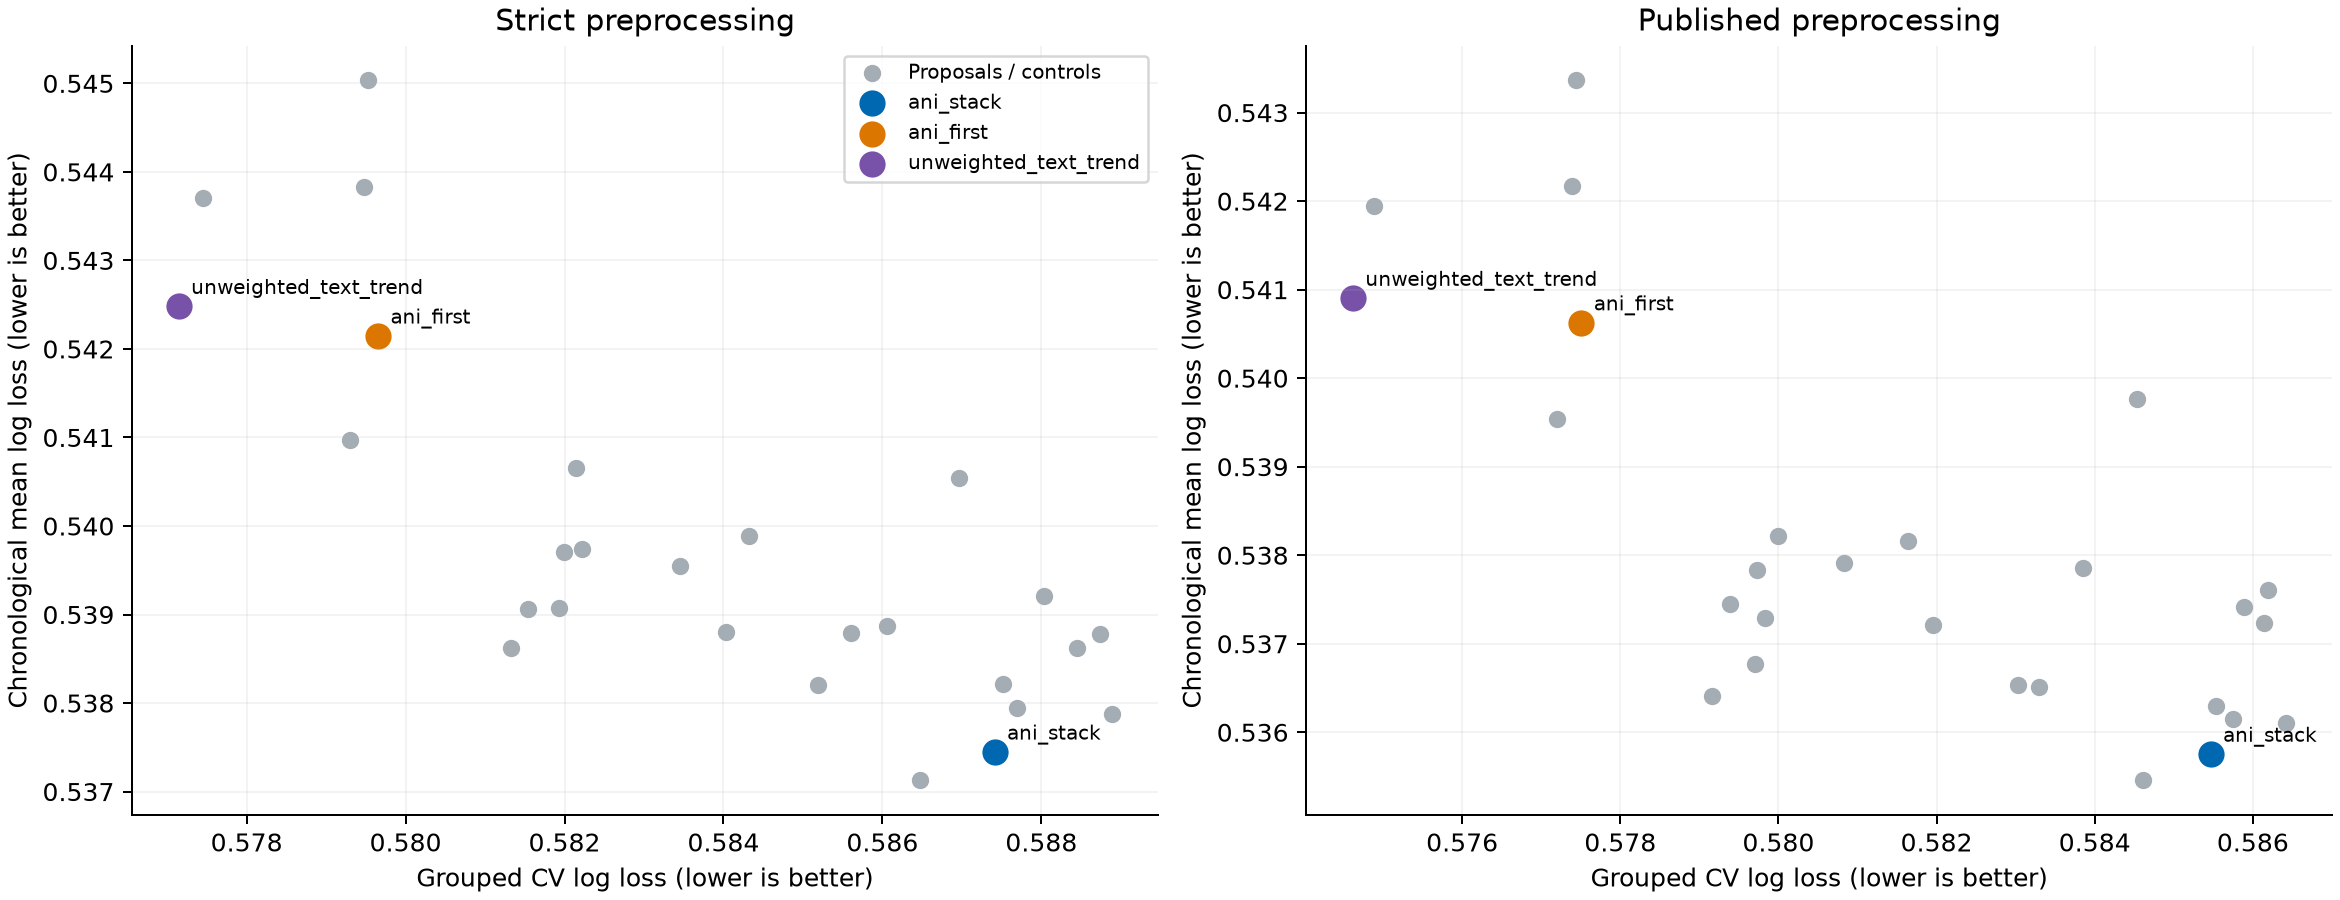

In [2]:
for track in ['strict', 'published']:
    print(track)
    display(pd.read_csv(run / 'text_followup' / track / 'independent_summary.csv').sort_values('temporal').round(6))
display(Image(filename=str(run / 'figures/tradeoffs.png')))

## Paired differences against both winners

Negative favors the proposal; intervals crossing zero are inconclusive. Resampling keeps trial rows together and does not count repeat appearances as independent trials.

,track,model,reference,kind,delta,lower,upper,trials,bootstrap_repetitions
40,strict,ani_phase3_trend,ani_stack,temporal,-0.000315,-0.001116,0.000466,3478,2000
41,strict,ani_phase3_trend,ani_stack,group_cv,-0.000943,-0.002212,0.000325,8436,2000
42,strict,ani_phase3_trend,ani_first,temporal,-0.005015,-0.008686,-0.001390,3478,2000
43,strict,ani_phase3_trend,ani_first,group_cv,0.006815,0.003899,0.009882,8436,2000
88,strict,recent_text_stack,ani_stack,temporal,0.002443,-0.001610,0.006452,3478,2000
89,strict,recent_text_stack,ani_stack,group_cv,-0.003085,-0.004806,-0.001360,8436,2000
90,strict,recent_text_stack,ani_first,temporal,-0.002256,-0.007007,0.002953,3478,2000
91,strict,recent_text_stack,ani_first,group_cv,0.004673,0.001508,0.007872,8436,2000
144,published,ani_phase3_trend,ani_stack,temporal,-0.000291,-0.001079,0.000488,3478,2000
145,published,ani_phase3_trend,ani_stack,group_cv,-0.000858,-0.002112,0.000392,8436,2000


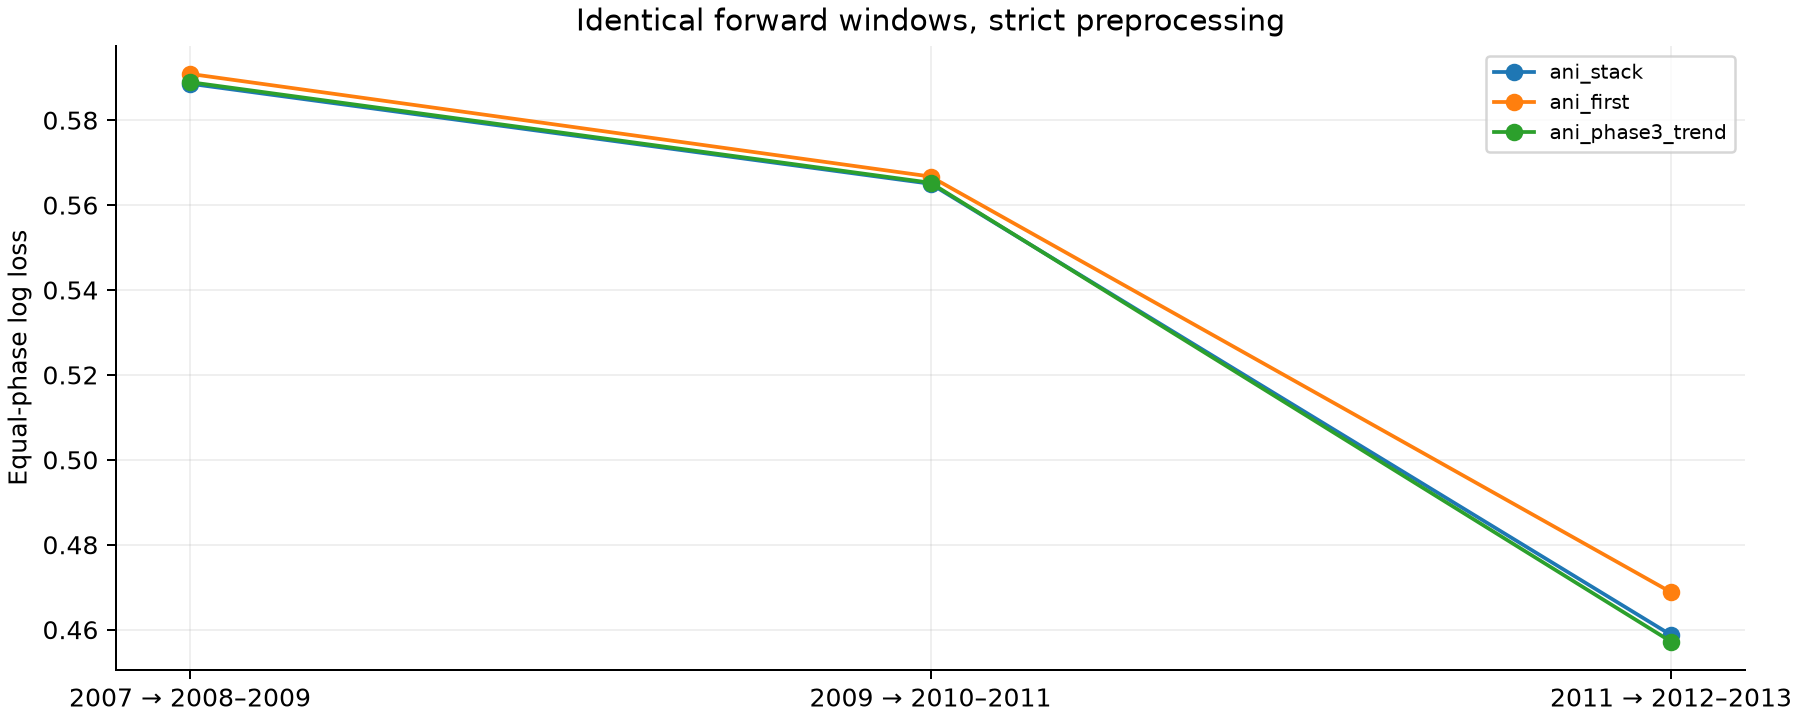

In [3]:
pairs = pd.read_csv(run / 'paired_comparisons.csv')
shortlist = json.loads((run / 'selection.json').read_text())['shortlist']
focus = shortlist or ['ani_phase3_trend', 'recent_text_stack']
display(pairs[pairs.model.isin(focus)].round(6))
display(Image(filename=str(run / 'figures/chronological.png')))

## Additional time gaps and verification

These reuse historical labels; they are robustness checks, not untouched validation. Only the frozen shortlist and both references are evaluated.

In [4]:
for track in ['strict','published']:
    print(track)
    display(pd.read_csv(run / 'robustness' / track / 'summary.csv').round(6))
display(json.loads((run / 'verification.json').read_text()))
display(json.loads((root / 'submissions/stack_improvements_manifest.json').read_text()))

strict


,model,completed_splits,official,temporal,worst,cv
0,ani_first,3,NaN,0.568041,0.633776,NaN
1,ani_stack,3,NaN,0.564681,0.630298,NaN


published


,model,completed_splits,official,temporal,worst,cv
0,ani_first,3,NaN,0.568040,0.633129,NaN
1,ani_stack,3,NaN,0.563803,0.628274,NaN


{'run': '097ac8161372126d',
 'recipe_count': 27,
 'tracks': 2,
 'splits_per_track': 10,
 'source_hashes_match': True,
 'original_protocol_unchanged': True,
 'fitted_boundaries_verified': True,
 'historical_baseline_max_probability_error': 0.0,
 'both_kaggle_sources_reproduced': {'ani_stack': {'source_sha256': '17caa6b02af919c8ba6358d680075208ba8d4f1d11c20d5b6d06e8f6d494b3c2',
   'max_probability_error': 3.542518944854578e-09},
  'ani_first': {'source_sha256': '63a5ed6154c6c96cb838c27fa7feb2656a24960362a1c69be05cd6c3d7c789e5',
   'max_probability_error': 2.4297228318204134e-07}},
 'gapped_windows_verified': 6,
 'shortlist': [],
 'new_submissions': 0,
 'independently_rescored_predictions': 540}

{'status': 'No proposal passed the predeclared rule; no new numbered submission exported. Retain Ani 0.58688.',
 'submissions': [],
 'source_parity': {'ani_stack': {'source_sha256': '17caa6b02af919c8ba6358d680075208ba8d4f1d11c20d5b6d06e8f6d494b3c2',
   'max_probability_error': 3.542518944854578e-09},
  'ani_first': {'source_sha256': '63a5ed6154c6c96cb838c27fa7feb2656a24960362a1c69be05cd6c3d7c789e5',
   'max_probability_error': 2.4297228318204134e-07}}}